In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

# Load dataset
df = pd.read_csv(r"C:\Users\hp\Downloads\Test-selected-columns.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (5681, 10)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type
0,FDW58,20.750,Low Fat,0.007565,Snack Foods,107.8622,OUT049,1999,Medium,Tier 1
1,FDW14,8.300,reg,0.038428,Dairy,87.3198,OUT017,2007,NaN,Tier 2
2,NCN55,14.600,Low Fat,0.099575,Others,241.7538,OUT010,1998,NaN,Tier 3
3,FDQ58,7.315,Low Fat,0.015388,Snack Foods,155.0340,OUT017,2007,NaN,Tier 2
4,FDY38,NaN,Regular,0.118599,Dairy,234.2300,OUT027,1985,Medium,Tier 3


In [9]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Columns:
['Item_Identifier', 'Item_Weight', 'Item_Fat_Content', 'Item_Visibility', 'Item_Type', 'Item_MRP', 'Outlet_Identifier', 'Outlet_Establishment_Year', 'Outlet_Size', 'Outlet_Location_Type']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5681 entries, 0 to 5680
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            5681 non-null   object 
 1   Item_Weight                4705 non-null   float64
 2   Item_Fat_Content           5681 non-null   object 
 3   Item_Visibility            5681 non-null   float64
 4   Item_Type                  5681 non-null   object 
 5   Item_MRP                   5681 non-null   float64
 6   Outlet_Identifier          5681 non-null   object 
 7   Outlet_Establishment_Year  5681 non-null   int64  
 8   Outlet_Size                4075 non-null   object 
 9   Outlet_Location_Type       5681 non-null   object 
dt

In [5]:
print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())


First 5 rows:


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type
0,FDW58,20.750,Low Fat,0.007565,Snack Foods,107.8622,OUT049,1999,Medium,Tier 1,Supermarket Type1
1,FDW14,8.300,reg,0.038428,Dairy,87.3198,OUT017,2007,NaN,Tier 2,Supermarket Type1
2,NCN55,14.600,Low Fat,0.099575,Others,241.7538,OUT010,1998,NaN,Tier 3,Grocery Store
3,FDQ58,7.315,Low Fat,0.015388,Snack Foods,155.0340,OUT017,2007,NaN,Tier 2,Supermarket Type1
4,FDY38,NaN,Regular,0.118599,Dairy,234.2300,OUT027,1985,Medium,Tier 3,Supermarket Type3



Last 5 rows:


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type
5676,FDB58,10.5,Regular,0.013496,Snack Foods,141.3154,OUT046,1997,Small,Tier 1,Supermarket Type1
5677,FDD47,7.6,Regular,0.142991,Starchy Foods,169.1448,OUT018,2009,Medium,Tier 3,Supermarket Type2
5678,NCO17,10.0,Low Fat,0.073529,Health and Hygiene,118.7440,OUT045,2002,NaN,Tier 2,Supermarket Type1
5679,FDJ26,15.3,Regular,0.000000,Canned,214.6218,OUT017,2007,NaN,Tier 2,Supermarket Type1
5680,FDU37,9.5,Regular,0.104720,Canned,79.7960,OUT045,2002,NaN,Tier 2,Supermarket Type1


In [11]:
# Make a copy of the original data
clean_df = df.copy()

# Handle missing Item Weight using median
clean_df["Item_Weight"] = clean_df["Item_Weight"].fillna(
    clean_df["Item_Weight"].median()
)

# Handle missing Outlet Size using the most frequent value
clean_df["Outlet_Size"] = clean_df["Outlet_Size"].fillna(
    clean_df["Outlet_Size"].mode()[0]
)

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

print("Missing values after cleaning:")
print(clean_df.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(clean_df.duplicated().sum())

Missing values after cleaning:
Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
dtype: int64

Duplicate rows after cleaning:
0


In [17]:
categorical_columns = [
    "Item_Fat_Content",
    "Item_Type",
    "Outlet_Identifier",
    "Outlet_Size",
    "Outlet_Location_Type"
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(clean_df[col].value_counts())


Item_Fat_Content:
Item_Fat_Content
Low Fat    3668
Regular    2013
Name: count, dtype: int64

Item_Type:
Item_Type
Snack Foods              789
Fruits and Vegetables    781
Household                638
Frozen Foods             570
Dairy                    454
Baking Goods             438
Canned                   435
Health and Hygiene       338
Meat                     311
Soft Drinks              281
Breads                   165
Hard Drinks              148
Starchy Foods            121
Others                   111
Breakfast                 76
Seafood                   25
Name: count, dtype: int64

Outlet_Identifier:
Outlet_Identifier
OUT027    624
OUT013    621
OUT049    620
OUT046    620
OUT035    620
OUT045    619
OUT018    618
OUT017    617
OUT010    370
OUT019    352
Name: count, dtype: int64

Outlet_Size:
Outlet_Size
Medium    3468
Small     1592
High       621
Name: count, dtype: int64

Outlet_Location_Type:
Outlet_Location_Type
Tier 3    2233
Tier 2    1856
Tier 1    1592
Name

In [14]:
clean_df["Item_Fat_Content"] = clean_df["Item_Fat_Content"].replace({
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "reg": "Regular"
})

print(clean_df["Item_Fat_Content"].value_counts())

Item_Fat_Content
Low Fat    3668
Regular    2013
Name: count, dtype: int64


In [19]:
clean_df["Item_Fat_Content"] = clean_df["Item_Fat_Content"].replace({
    "LF": "Low Fat",
    "low fat": "Low Fat",
    "reg": "Regular"
})

print(clean_df["Item_Fat_Content"].value_counts())

Item_Fat_Content
Low Fat    3668
Regular    2013
Name: count, dtype: int64


In [21]:
print("Dataset Shape:", clean_df.shape)

print("\nTotal Missing Values:",
      clean_df.isnull().sum().sum())

print("Total Duplicate Rows:",
      clean_df.duplicated().sum())

print("\nFat Content Categories:")
print(clean_df["Item_Fat_Content"].unique())

Dataset Shape: (5681, 10)

Total Missing Values: 0
Total Duplicate Rows: 0

Fat Content Categories:
['Low Fat' 'Regular']


In [23]:
# Automated Summary Report

summary_report = {
    "Total Records": len(clean_df),
    "Total Items": clean_df["Item_Identifier"].nunique(),
    "Total Outlets": clean_df["Outlet_Identifier"].nunique(),
    "Total Item Types": clean_df["Item_Type"].nunique(),
    "Average Item Weight": round(clean_df["Item_Weight"].mean(), 2),
    "Average Item MRP": round(clean_df["Item_MRP"].mean(), 2),
    "Average Item Visibility": round(clean_df["Item_Visibility"].mean(), 4),
    "Most Common Item Type": clean_df["Item_Type"].mode()[0],
    "Most Common Fat Content": clean_df["Item_Fat_Content"].mode()[0],
    "Most Common Outlet Size": clean_df["Outlet_Size"].mode()[0],
    "Most Common Location": clean_df["Outlet_Location_Type"].mode()[0]
}

summary_df = pd.DataFrame(
    summary_report.items(),
    columns=["Metric", "Value"]
)

summary_df

,Metric,Value
0,Total Records,5681
1,Total Items,1543
2,Total Outlets,10
3,Total Item Types,16
4,Average Item Weight,12.66
5,Average Item MRP,141.02
6,Average Item Visibility,0.0657
7,Most Common Item Type,Snack Foods
8,Most Common Fat Content,Low Fat
9,Most Common Outlet Size,Medium


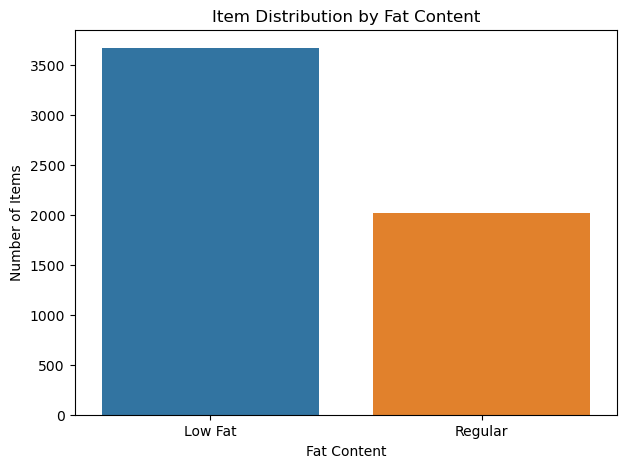

In [25]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=clean_df,
    x="Item_Fat_Content"
)

plt.title("Item Distribution by Fat Content")
plt.xlabel("Fat Content")
plt.ylabel("Number of Items")
plt.show()

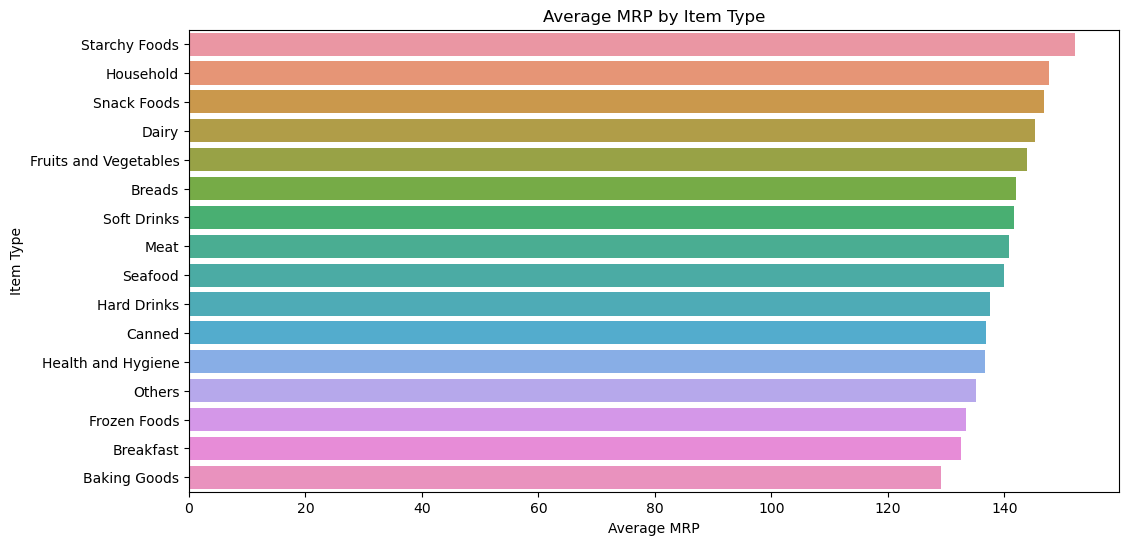

In [27]:
avg_mrp = (
    clean_df.groupby("Item_Type")["Item_MRP"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=avg_mrp.values,
    y=avg_mrp.index
)

plt.title("Average MRP by Item Type")
plt.xlabel("Average MRP")
plt.ylabel("Item Type")
plt.show()

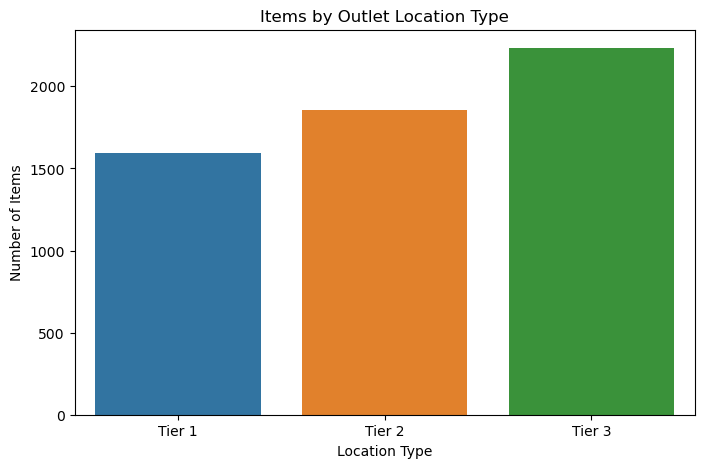

In [29]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=clean_df,
    x="Outlet_Location_Type"
)

plt.title("Items by Outlet Location Type")
plt.xlabel("Location Type")
plt.ylabel("Number of Items")
plt.show()

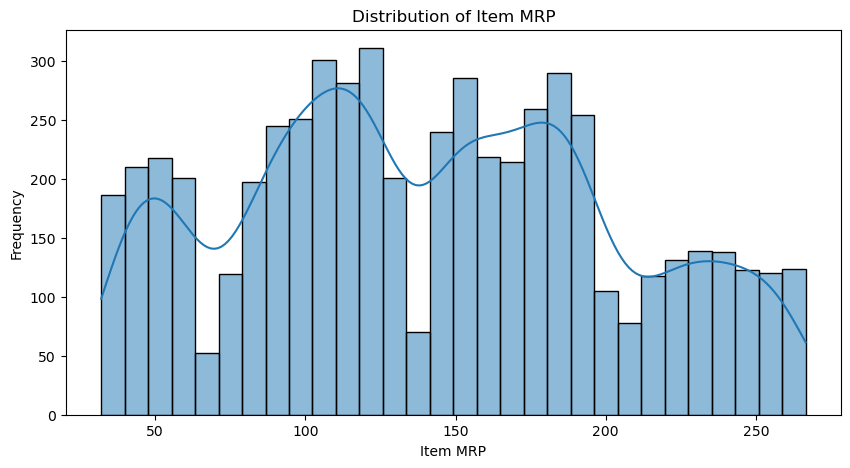

In [31]:
plt.figure(figsize=(10, 5))

sns.histplot(
    clean_df["Item_MRP"],
    bins=30,
    kde=True
)

plt.title("Distribution of Item MRP")
plt.xlabel("Item MRP")
plt.ylabel("Frequency")
plt.show()